# Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

PRETRAINED_MODELS_RESULTS_CSV = 'results/modelsubject_correlations_nsd515.csv'

TRAINED_MODELS_DICT = {
    'rn18_imgnet_finetuned_faceclassification': "/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_classification/evaluation/f5b95b1f-31fd-47c4-a6fb-2e52f709349a",
    'rn18_scratch_faceclassification': "/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_classification/evaluation/f2c52f72-351f-4a13-9865-209d6edacf56"
}

MODEL_FMRI_FROIS = [
    ('FFA', 'FFA'),
    ('PPA', 'PPA'),
    ('EBA', 'EBA'),
]
MODEL_LOCALIZER = 'grillspector'
TTHRESHOLD = 7

COLORS = ['royalblue', 'green', 'orange', 'pink', 'brown']

pretrained_results_csv = pd.read_csv(PRETRAINED_MODELS_RESULTS_CSV)

In [2]:
# Util functions

def plot_groupwise_comparison(groups, title, median_subjects=False):
    """
    Plot groupwise comparison of NSD515 similarity
    :param groups: List of dictionaries containing group directories and labels
    :return: None
    """
    froi_pearsonrs_plot_data = {}
    for (model_froi, fmri_froi) in MODEL_FMRI_FROIS:
        assert model_froi == fmri_froi, \
            "Model and fMRI fROIs should be the same, alternative not yet implemented"
        froi_pearsonrs_plot_data[model_froi] = {}
        for group_name, group_dirs in groups.items():
            if group_name.startswith('pretrained'):
                # ResNet18 trained on ImageNet
                pretrained_group_pearsonrs = pretrained_results_csv[
                    (pretrained_results_csv['model_name'] == group_name.replace("pretrained_", "")) &
                    (pretrained_results_csv['model_froi'] == model_froi) &
                    (pretrained_results_csv['fmri_froi'] == fmri_froi) &
                    (pretrained_results_csv['fmri_tthreshold'] == TTHRESHOLD) &
                    (pretrained_results_csv['model_localizer'] == MODEL_LOCALIZER) &
                    (pretrained_results_csv['model_tthreshold'] == TTHRESHOLD)
                ]['normed_pearsonr'].tolist()
                corrs = pretrained_group_pearsonrs
                if median_subjects:
                    # Get the median across subjects
                    corrs = [np.median(corrs)]
                froi_pearsonrs_plot_data[model_froi][group_name.replace("pretrained_", "")] = corrs
            else:
                for model_dir in group_dirs:
                    # Load the data
                    corrs_df = pd.read_csv(f'{model_dir}/nsd515_correlations.csv')
                    corrs = corrs_df[
                        (corrs_df['model_froi'] == model_froi) &
                        (corrs_df['fmri_froi'] == fmri_froi) &
                        (corrs_df['fmri_tthreshold'] == TTHRESHOLD) &
                        (corrs_df['model_localizer'] == MODEL_LOCALIZER) &
                        (corrs_df['model_tthreshold'] == TTHRESHOLD)
                    ]['normed_pearsonr'].tolist()
                    corrs = [float(x) for x in corrs]
                    # Append the results
                    if group_name not in froi_pearsonrs_plot_data[model_froi]:
                        froi_pearsonrs_plot_data[model_froi][group_name] = []
                    if median_subjects:
                        # Get the median across subjects
                        corrs = [np.median(corrs)]
                    froi_pearsonrs_plot_data[model_froi][group_name] += corrs
    fig, ax = plt.subplots(1, 2, figsize=(10, 6))
    colors = COLORS[:len(groups)]
    labels = list(froi_pearsonrs_plot_data[list(froi_pearsonrs_plot_data.keys())[0]].keys())
    labels = [lbl.replace('pretrained_', '') for lbl in labels]
    for xidx, (model_froi, fmri_froi) in enumerate(froi_pearsonrs_plot_data.items()):
        froi_pearsonrs = froi_pearsonrs_plot_data[model_froi]
        for idx, (_, pearsonrs) in enumerate(froi_pearsonrs.items()):
            xpt = xidx + 0.25 * (idx - 1)
            ax[0].bar(
                xpt, np.median(pearsonrs), yerr=stats.sem(pearsonrs), alpha=0.5, \
                label=model_froi, color=colors[idx], width=0.25
            )
            ax[0].scatter(
                np.array([xpt]*len(pearsonrs))-0.05, pearsonrs, color=colors[idx], alpha=0.5, ec='k'
            )
    ax[0].set_ylim(-0.05, 1)
    ax[0].set_xticks(np.arange(len(froi_pearsonrs_plot_data)), froi_pearsonrs_plot_data.keys())
    ax[0].set_ylabel(r'Median pearson $\rho$ with NSD 515')
    ax[0].set_xlabel('fROI')
    ax[0].set_title(title)
    ax[0].spines['top'].set_visible(False)
    ax[0].spines['right'].set_visible(False)
    ax[0].legend(labels)
    # RDMr
    froi_rdmrs_plot_data = {}
    for (model_froi, fmri_froi) in MODEL_FMRI_FROIS:
        assert model_froi == fmri_froi, \
            "Model and fMRI fROIs should be the same, alternative not yet implemented"
        froi_rdmrs_plot_data[model_froi] = {}
        for group_name, group_dirs in groups.items():
            if group_name.startswith('pretrained'):
                # ResNet18 trained on ImageNet
                pretrained_group_rdmrs = pretrained_results_csv[
                    (pretrained_results_csv['model_name'] == group_name.replace("pretrained_", "")) &
                    (pretrained_results_csv['model_froi'] == model_froi) &
                    (pretrained_results_csv['fmri_froi'] == fmri_froi) &
                    (pretrained_results_csv['fmri_tthreshold'] == TTHRESHOLD) &
                    (pretrained_results_csv['model_localizer'] == MODEL_LOCALIZER) &
                    (pretrained_results_csv['model_tthreshold'] == TTHRESHOLD)
                ]['normed_rdmr'].tolist()
                corrs = pretrained_group_rdmrs
                if median_subjects:
                    # Get the median across subjects
                    corrs = [np.median(corrs)]
                froi_rdmrs_plot_data[model_froi][group_name.replace("pretrained_", "")] = corrs
            else:
                for model_dir in group_dirs:
                    # Load the data
                    corrs_df = pd.read_csv(f'{model_dir}/nsd515_correlations.csv')
                    corrs = corrs_df[
                        (corrs_df['model_froi'] == model_froi) &
                        (corrs_df['fmri_froi'] == fmri_froi) &
                        (corrs_df['fmri_tthreshold'] == TTHRESHOLD) &
                        (corrs_df['model_localizer'] == MODEL_LOCALIZER) &
                        (corrs_df['model_tthreshold'] == TTHRESHOLD)
                    ]['normed_rdmr'].tolist()
                    corrs = [float(x) for x in corrs]
                    # Append the results
                    if group_name not in froi_rdmrs_plot_data[model_froi]:
                        froi_rdmrs_plot_data[model_froi][group_name] = []
                    if median_subjects:
                        # Get the median across subjects
                        corrs = [np.median(corrs)]
                    froi_rdmrs_plot_data[model_froi][group_name] += corrs
    colors = COLORS[:len(groups)]
    labels = list(froi_rdmrs_plot_data[list(froi_rdmrs_plot_data.keys())[0]].keys())
    labels = [lbl.replace('pretrained_', '') for lbl in labels]
    for xidx, (model_froi, fmri_froi) in enumerate(froi_rdmrs_plot_data.items()):
        froi_rdmrs = froi_rdmrs_plot_data[model_froi]
        for idx, (_, rdmrs) in enumerate(froi_rdmrs.items()):
            xpt = xidx + 0.25 * (idx - 1)
            ax[1].bar(
                xpt, np.median(rdmrs), yerr=stats.sem(rdmrs), alpha=0.5, \
                label=model_froi, color=colors[idx], width=0.25
            )
            ax[1].scatter(
                np.array([xpt]*len(rdmrs))-0.05, rdmrs, color=colors[idx], alpha=0.5, ec='k'
            )
    ax[1].set_ylim(-0.05, 1)
    ax[1].set_xticks(np.arange(len(froi_rdmrs_plot_data)), froi_rdmrs_plot_data.keys())
    ax[1].set_ylabel(r'Median RDM $\rho$ with NSD 515')
    ax[1].set_xlabel('fROI')
    ax[1].set_title(title)
    ax[1].spines['top'].set_visible(False)
    ax[1].spines['right'].set_visible(False)
    ax[1].legend(labels)
    plt.tight_layout()
    plt.show()

# Face Contrastive

/tmp/ipykernel_2520214/1598020395.py:58: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(pearsonrs), yerr=stats.sem(pearsonrs), alpha=0.5, \
/tmp/ipykernel_2520214/1598020395.py:121: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(rdmrs), yerr=stats.sem(rdmrs), alpha=0.5, \


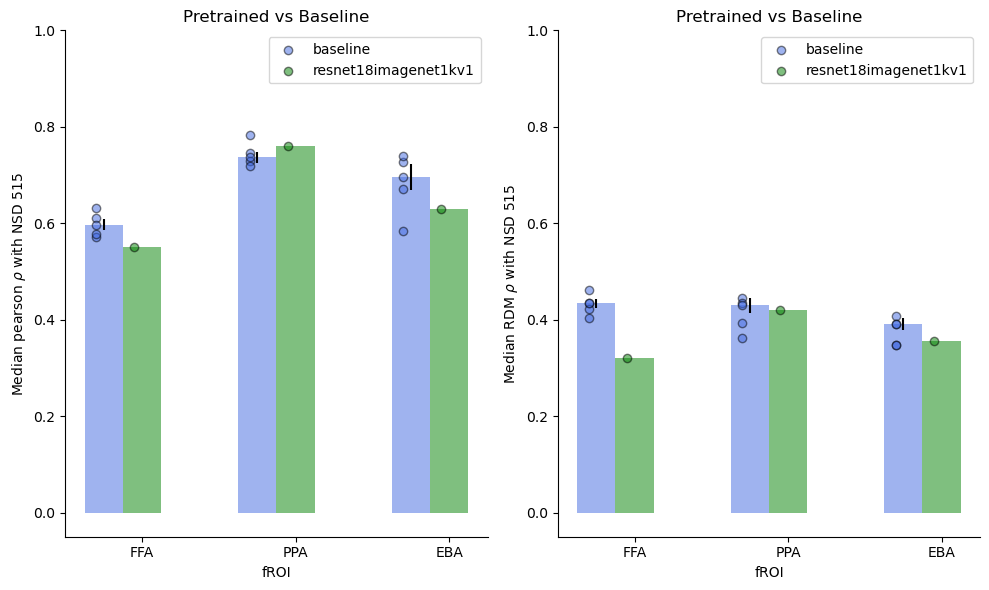

In [13]:
COMPARISON_PRETRAINED_BASELINE = {
    'baseline': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/07b23b77-d466-4742-b831-1298411e7288',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/3f108f6e-5475-49b0-9879-d1865e2110dc',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/45f6d793-4f37-4312-aa26-9fc6d1bb99a8',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/6bb52e1e-6ceb-457a-a622-d92572c430b5',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/7973cdaa-988f-45f8-9cdf-54b38845004e',
    ],
    'pretrained_resnet18imagenet1kv1': PRETRAINED_MODELS_RESULTS_CSV,
}
plot_groupwise_comparison(
    COMPARISON_PRETRAINED_BASELINE,
    'Pretrained vs Baseline',
    median_subjects=True
)

/tmp/ipykernel_704827/1748350255.py:59: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(pearsonrs), yerr=stats.sem(pearsonrs), alpha=0.5, \


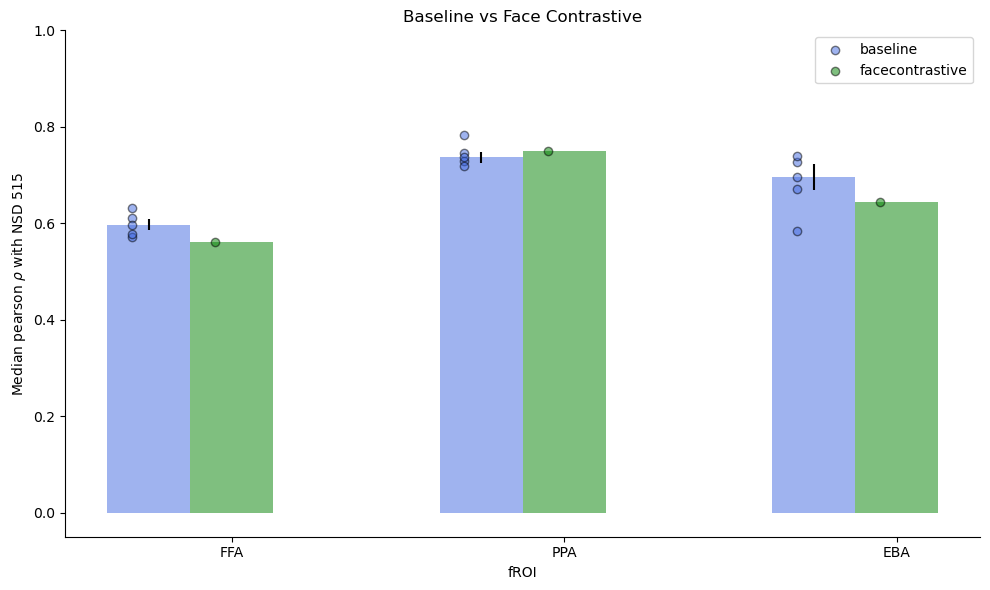

In [ ]:
COMPARISON_BASELINE_FACECONTRASTIVE_TMP = {
    'baseline': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/07b23b77-d466-4742-b831-1298411e7288',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/3f108f6e-5475-49b0-9879-d1865e2110dc',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/45f6d793-4f37-4312-aa26-9fc6d1bb99a8',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/6bb52e1e-6ceb-457a-a622-d92572c430b5',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/7973cdaa-988f-45f8-9cdf-54b38845004e',
    ],
    'facecontrastive': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/98a7d4ed-9919-40b5-9766-0c5e574c2423_epoch11',
    ]
}
plot_groupwise_comparison(
    COMPARISON_BASELINE_FACECONTRASTIVE_TMP,
    'Baseline vs Face Contrastive',
    median_subjects=True
)

/tmp/ipykernel_605825/1748350255.py:59: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(pearsonrs), yerr=stats.sem(pearsonrs), alpha=0.5, \


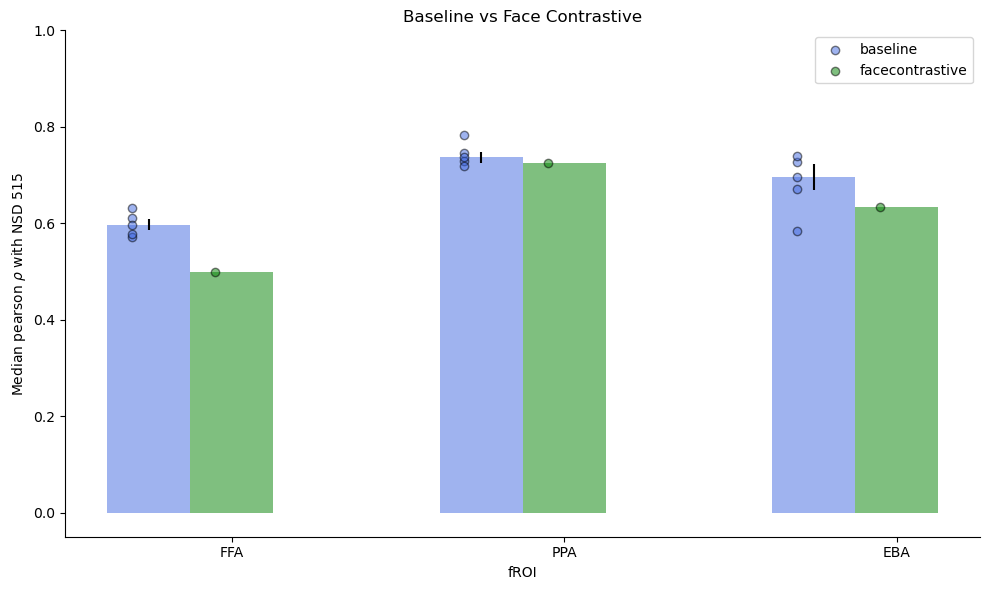

In [ ]:
COMPARISON_BASELINE_FACECONTRASTIVE_TMP2 = {
    'baseline': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/07b23b77-d466-4742-b831-1298411e7288',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/3f108f6e-5475-49b0-9879-d1865e2110dc',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/45f6d793-4f37-4312-aa26-9fc6d1bb99a8',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/6bb52e1e-6ceb-457a-a622-d92572c430b5',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/7973cdaa-988f-45f8-9cdf-54b38845004e',
    ],
    'facecontrastive': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/e8768a3b-b9dc-4ed6-a30d-dba5f15cfe27_epoch46',
    ]
}
plot_groupwise_comparison(
    COMPARISON_BASELINE_FACECONTRASTIVE_TMP2,
    'Baseline vs Face Contrastive',
    median_subjects=True
)

/tmp/ipykernel_605825/1748350255.py:59: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(pearsonrs), yerr=stats.sem(pearsonrs), alpha=0.5, \


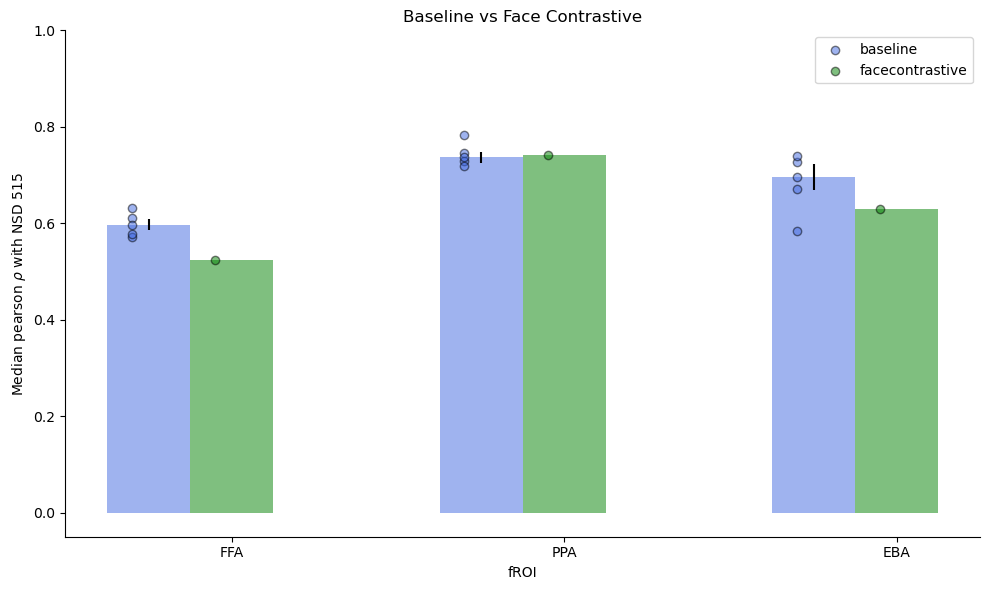

In [ ]:
COMPARISON_BASELINE_FACECONTRASTIVE_TMP3 = {
    'baseline': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/07b23b77-d466-4742-b831-1298411e7288',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/3f108f6e-5475-49b0-9879-d1865e2110dc',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/45f6d793-4f37-4312-aa26-9fc6d1bb99a8',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/6bb52e1e-6ceb-457a-a622-d92572c430b5',
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/7973cdaa-988f-45f8-9cdf-54b38845004e',
    ],
    'facecontrastive': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/e8390aa7-fba7-48af-a7d4-4e07a2459f14_epoch60',
    ]
}
plot_groupwise_comparison(
    COMPARISON_BASELINE_FACECONTRASTIVE_TMP3,
    'Baseline vs Face Contrastive',
    median_subjects=True
)

/tmp/ipykernel_2520214/1598020395.py:58: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(pearsonrs), yerr=stats.sem(pearsonrs), alpha=0.5, \
/tmp/ipykernel_2520214/1598020395.py:121: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(rdmrs), yerr=stats.sem(rdmrs), alpha=0.5, \


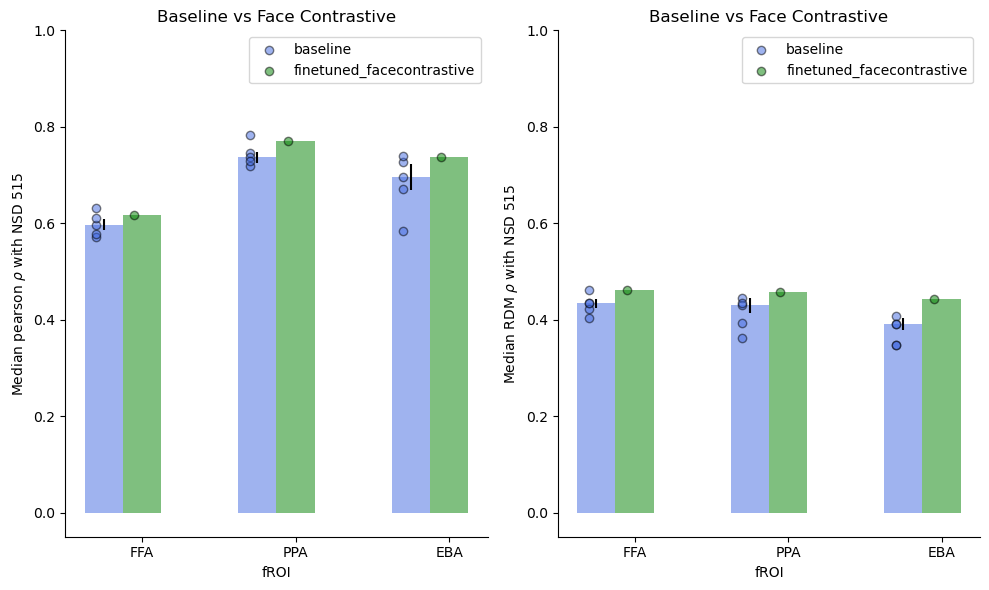

In [ ]:
# hopt5
# Face Contrastive, resnet18 imagenet1kv1 finetuned, lw0.5 tmp0.1, res 160 -> 192, val cont loss = 1.34, val top 1 = 0.567
COMPARISON_BASELINE_FACECONTRASTIVE_TMP4 = {
    'baseline': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/07b23b77-d466-4742-b831-1298411e7288', # seed0, gseed42, mseed42
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/3f108f6e-5475-49b0-9879-d1865e2110dc', # seed1, gseed12, mseed54
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/6bb52e1e-6ceb-457a-a622-d92572c430b5', # seed2, gseed23, mseed35
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/7973cdaa-988f-45f8-9cdf-54b38845004e', # seed3, gseed2, mseed84
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/45f6d793-4f37-4312-aa26-9fc6d1bb99a8', # seed4, gseed63, mseed92
    ],
    'finetuned_facecontrastive': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/1cead616-f96e-4dbf-a4c6-4ce58bf625aa_epochfinal',
    ],
    # 'sc_facecontrastive': [
    #     '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/e8768a3b-b9dc-4ed6-a30d-dba5f15cfe27_epoch46',
    # ]
}
plot_groupwise_comparison(
    COMPARISON_BASELINE_FACECONTRASTIVE_TMP4,
    'Baseline vs Face Contrastive',
    median_subjects=True
)

/tmp/ipykernel_2520214/1598020395.py:58: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(pearsonrs), yerr=stats.sem(pearsonrs), alpha=0.5, \
/tmp/ipykernel_2520214/1598020395.py:121: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(rdmrs), yerr=stats.sem(rdmrs), alpha=0.5, \


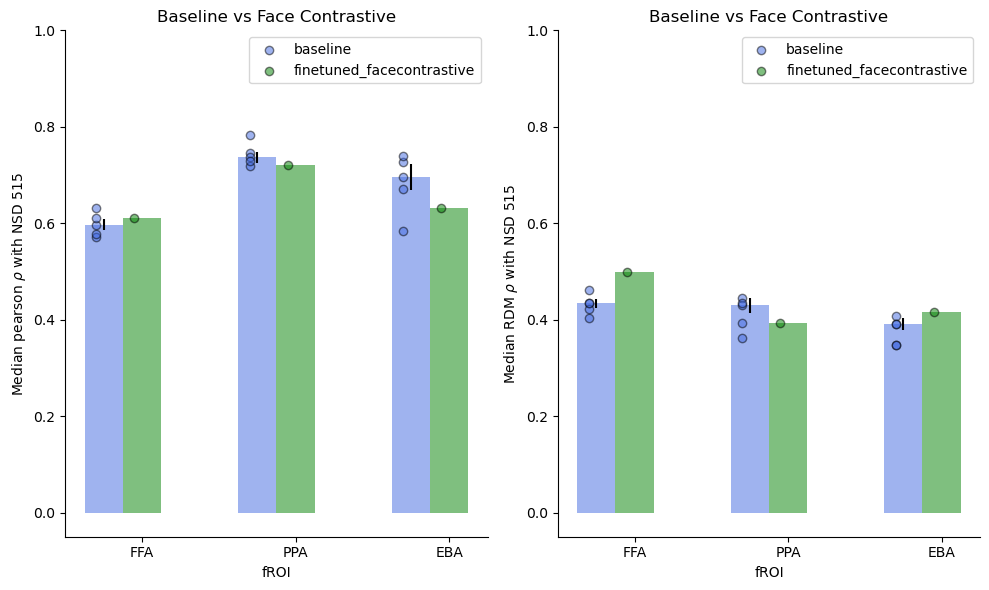

In [ ]:
# hopt6
# Face Contrastive, finetuned, lw0.5 tmp0.1, res 224, epoch 78, val cont loss = 0.649, val top 1 = 0.50
COMPARISON_BASELINE_FACECONTRASTIVE_TMP5 = {
    'baseline': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/07b23b77-d466-4742-b831-1298411e7288', # seed0, gseed42, mseed42
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/3f108f6e-5475-49b0-9879-d1865e2110dc', # seed1, gseed12, mseed54
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/6bb52e1e-6ceb-457a-a622-d92572c430b5', # seed2, gseed23, mseed35
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/7973cdaa-988f-45f8-9cdf-54b38845004e', # seed3, gseed2, mseed84
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/45f6d793-4f37-4312-aa26-9fc6d1bb99a8', # seed4, gseed63, mseed92
    ],
    'finetuned_facecontrastive': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/6a3dab82-855f-432c-803c-19fc068be407_epoch78',
    ],
    # 'baseline_accmatched': [
    #     '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/07b23b77-d466-4742-b831-1298411e7288_epoch22', # seed0, gseed42, mseed42, epoch22
    # ],
}
plot_groupwise_comparison(
    COMPARISON_BASELINE_FACECONTRASTIVE_TMP5,
    'Baseline vs Face Contrastive',
    median_subjects=True
)

/tmp/ipykernel_3219614/1985953894.py:58: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(pearsonrs), yerr=stats.sem(pearsonrs), alpha=0.5, \
/tmp/ipykernel_3219614/1985953894.py:121: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(rdmrs), yerr=stats.sem(rdmrs), alpha=0.5, \


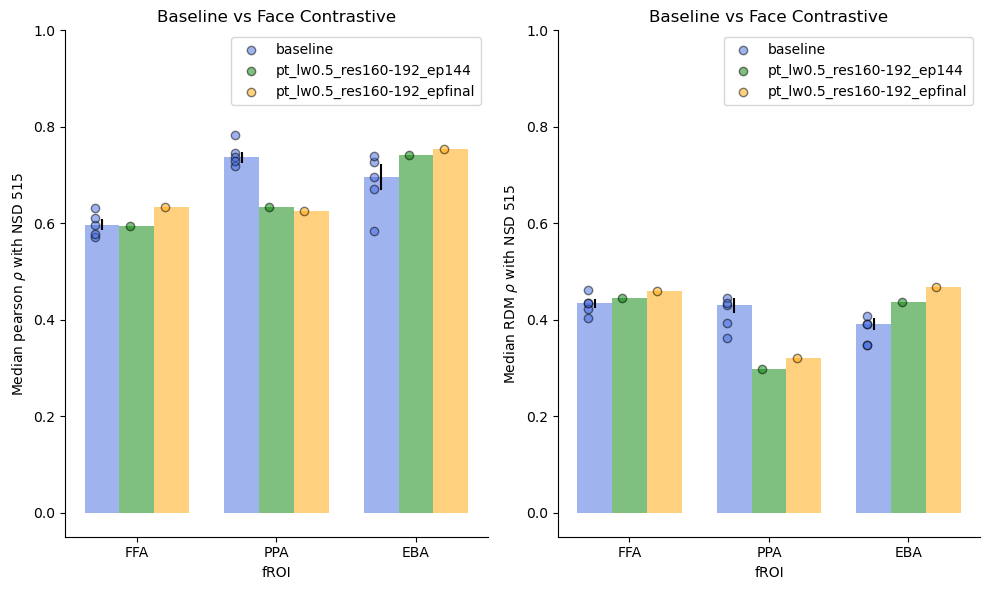

In [ ]:
# hopt6
# Face Contrastive, finetuned, lw0.5 tmp0.1, res 224, epoch 78, val cont loss = 0.649, val top 1 = 0.50
COMPARISON_BASELINE_FACECONTRASTIVE_6 = {
    'baseline': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/07b23b77-d466-4742-b831-1298411e7288', # seed0, gseed42, mseed42
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/3f108f6e-5475-49b0-9879-d1865e2110dc', # seed1, gseed12, mseed54
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/6bb52e1e-6ceb-457a-a622-d92572c430b5', # seed2, gseed23, mseed35
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/7973cdaa-988f-45f8-9cdf-54b38845004e', # seed3, gseed2, mseed84
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/45f6d793-4f37-4312-aa26-9fc6d1bb99a8', # seed4, gseed63, mseed92
    ],
    # 'pt_lw0.5_res160-192_ep144': [
    #     '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/d4e566aa-ce09-493f-92dc-cbe4c52a48ea_epoch144',
    # ],
    'pt_lw0.5_res160-192_epfinal': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/d4e566aa-ce09-493f-92dc-cbe4c52a48ea_epochfinal',
    ],
    'pt_lw0.5_res224_epfinal': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/6a3dab82-855f-432c-803c-19fc068be407_epochfinal',
    ],
    # 'sc_lw0.5_res224_ep125': [
    #     '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/ac2777cb-b60d-4b1a-ba79-6b9bd95ac644_epoch125',
    # ],
    # 'sc_lw0.5_res224_epfinal': [
    #     '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/ac2777cb-b60d-4b1a-ba79-6b9bd95ac644_epochfinal',
    # ],
}
plot_groupwise_comparison(
    COMPARISON_BASELINE_FACECONTRASTIVE_6,
    'Baseline vs Face Contrastive',
    median_subjects=True
)

/tmp/ipykernel_4062686/1985953894.py:58: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(pearsonrs), yerr=stats.sem(pearsonrs), alpha=0.5, \
/tmp/ipykernel_4062686/1985953894.py:121: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  xpt, np.median(rdmrs), yerr=stats.sem(rdmrs), alpha=0.5, \


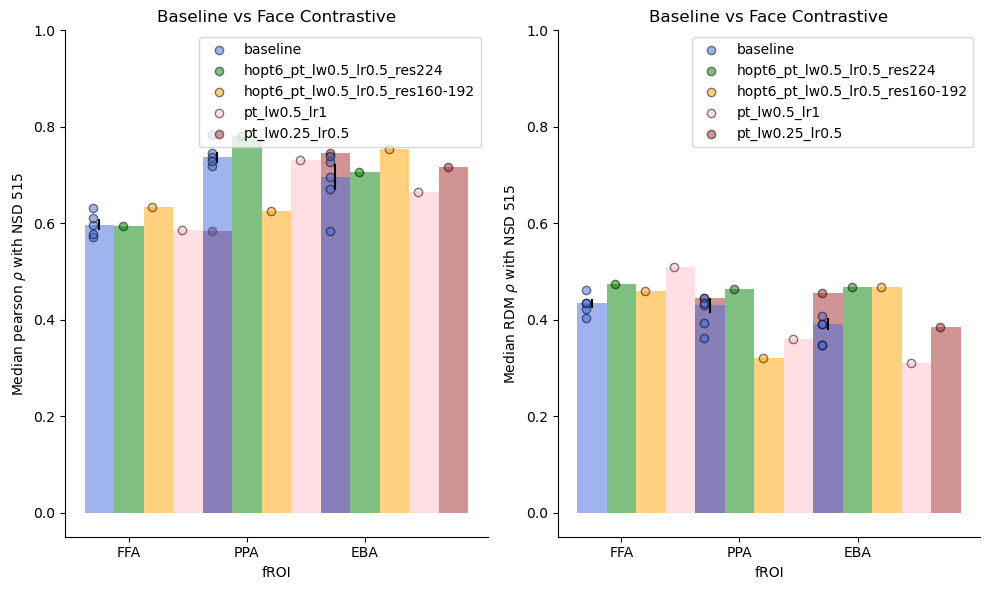

In [3]:
# hopt 7 (& 6)
# Face Contrastive, finetuned, lw0.25 tmp0.1 lr0.5, res 224, epoch 113, val cont loss = 0.64, val top 1 = 56
COMPARISON_BASELINE_FACECONTRASTIVE_HOPT7 = {
    'baseline': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/07b23b77-d466-4742-b831-1298411e7288', # seed0, gseed42, mseed42
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/3f108f6e-5475-49b0-9879-d1865e2110dc', # seed1, gseed12, mseed54
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/6bb52e1e-6ceb-457a-a622-d92572c430b5', # seed2, gseed23, mseed35
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/7973cdaa-988f-45f8-9cdf-54b38845004e', # seed3, gseed2, mseed84
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_baseline/evaluation/45f6d793-4f37-4312-aa26-9fc6d1bb99a8', # seed4, gseed63, mseed92
    ],
    # 'pt_lw0.25_lr0.5_res224_ep113': [
    #     '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/f8efb51a-0035-41af-87d1-d173782eb47f_epoch113',
    # ],
    'hopt6_pt_lw0.5_lr0.5_res224': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/6a3dab82-855f-432c-803c-19fc068be407_epochfinal',
    ],
    'hopt6_pt_lw0.5_lr0.5_res160-192': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/d4e566aa-ce09-493f-92dc-cbe4c52a48ea_epochfinal',
    ],
    'pt_lw0.5_lr1': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/e4af8785-636b-4db5-9de1-b552661ab3ff_epochfinal',
    ],
    'pt_lw0.25_lr0.5': [
        '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/f8efb51a-0035-41af-87d1-d173782eb47f_epochfinal',
    ],
    # 'pt_lw0.25_lr1': [
    #     '/om2/user/alishd/github/comparing-category-selectivity/preprint/trained_models/compcats_face_contrastive/evaluation/c7c66073-539e-458e-8350-2dab69c7f1bb_epochfinal',
    # ],
}
plot_groupwise_comparison(
    COMPARISON_BASELINE_FACECONTRASTIVE_HOPT7,
    'Baseline vs Face Contrastive',
    median_subjects=True
)

# Face Classification

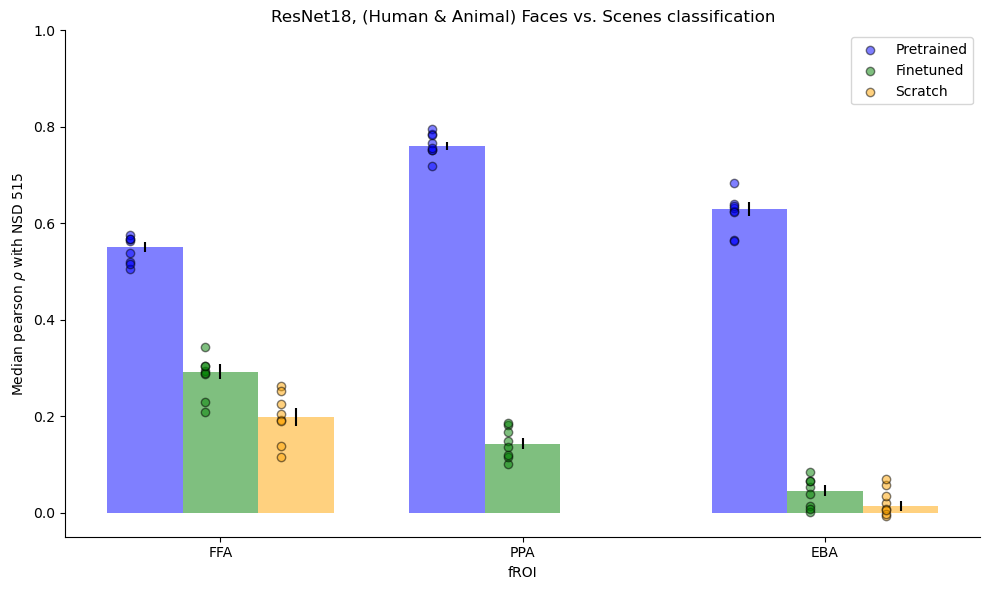

In [ ]:
# Pretrained ResNet18 vs. ResNet18 Face Classification (finetuned and scratch)

froi_pearsonrs_plot_data = {}
for (model_froi, fmri_froi) in MODEL_FMRI_FROIS:
    # ResNet18 trained on ImageNet
    resnet18_imagenet_pearsonrs = pretrained_results_csv[
        (pretrained_results_csv['model_name'] == 'resnet18imagenet1kv1') &
        (pretrained_results_csv['model_froi'] == model_froi) &
        (pretrained_results_csv['fmri_froi'] == fmri_froi) &
        (pretrained_results_csv['fmri_tthreshold'] == TTHRESHOLD) &
        (pretrained_results_csv['model_localizer'] == MODEL_LOCALIZER) &
        (pretrained_results_csv['model_tthreshold'] == TTHRESHOLD)
    ]['normed_pearsonr'].tolist()

    # ResNet18 trained on ImageNet and fine-tuned on face classification
    resnet18_imgenet_finetuned_fc_csv = pd.read_csv(
        TRAINED_MODELS_DICT['rn18_imgnet_finetuned_faceclassification'] + '/nsd515_correlations.csv'
    )
    resnet18_imgenet_finetuned_fc_pearsonrs = resnet18_imgenet_finetuned_fc_csv[
        (resnet18_imgenet_finetuned_fc_csv['model_froi'] == model_froi) &
        (resnet18_imgenet_finetuned_fc_csv['fmri_froi'] == fmri_froi) &
        (resnet18_imgenet_finetuned_fc_csv['fmri_tthreshold'] == TTHRESHOLD) &
        (resnet18_imgenet_finetuned_fc_csv['model_localizer'] == MODEL_LOCALIZER) &
        (resnet18_imgenet_finetuned_fc_csv['model_tthreshold'] == TTHRESHOLD)
    ]['normed_pearsonr'].tolist()
    resnet18_imgenet_finetuned_fc_pearsonrs = [float(x) for x in resnet18_imgenet_finetuned_fc_pearsonrs]

    # ResNet18 trained from scratch on face classification
    resnet18_scratch_fc_csv = pd.read_csv(
        TRAINED_MODELS_DICT['rn18_scratch_faceclassification'] + '/nsd515_correlations.csv'
    )
    resnet18_scratch_fc_pearsonrs = resnet18_scratch_fc_csv[
        (resnet18_scratch_fc_csv['model_froi'] == model_froi) &
        (resnet18_scratch_fc_csv['fmri_froi'] == fmri_froi) &
        (resnet18_scratch_fc_csv['fmri_tthreshold'] == TTHRESHOLD) &
        (resnet18_scratch_fc_csv['model_localizer'] == MODEL_LOCALIZER) &
        (resnet18_scratch_fc_csv['model_tthreshold'] == TTHRESHOLD)
    ]['normed_pearsonr'].tolist()
    resnet18_scratch_fc_pearsonrs = [float(x) for x in resnet18_scratch_fc_pearsonrs]
    
    # Store data for plotting
    froi_pearsonrs_plot_data[model_froi] = [
        resnet18_imagenet_pearsonrs,
        resnet18_imgenet_finetuned_fc_pearsonrs,
        resnet18_scratch_fc_pearsonrs
    ]

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['blue', 'green', 'orange']
labels = ['Pretrained', 'Finetuned', 'Scratch']
for xidx, (model_froi, fmri_froi) in enumerate(froi_pearsonrs_plot_data.items()):
    froi_pearsonrs = froi_pearsonrs_plot_data[model_froi]
    for idx, pearsonrs in enumerate(froi_pearsonrs):
        xpt = xidx + 0.25 * (idx - 1)
        ax.bar(
            xpt, np.median(pearsonrs), yerr=stats.sem(pearsonrs), alpha=0.5, \
            label=model_froi, color=colors[idx], width=0.25
        )
        ax.scatter(
            np.array([xpt]*len(pearsonrs))-0.05, pearsonrs, color=colors[idx], alpha=0.5, ec='k'
        )
ax.set_ylim(-0.05, 1)
ax.set_xticks(np.arange(len(froi_pearsonrs_plot_data)), froi_pearsonrs_plot_data.keys())
ax.set_ylabel(r'Median pearson $\rho$ with NSD 515')
ax.set_xlabel('fROI')
ax.set_title('ResNet18, (Human & Animal) Faces vs. Scenes classification')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(labels)
plt.tight_layout()
plt.show()